# HealthGPT (HealthLM) - a tiny GPT built from scratch (Colab)
Type a disease name, get common care tips. A small GPT-style model trained from scratch on `disease -> care` text.

> **Educational project only. Not medical advice. See a doctor.**

**Before you run:** Runtime -> Change runtime type -> **T4 GPU** (it also works on CPU, just slower). Then run all cells top to bottom (Runtime -> Run all).

Pipeline (same as your presentation):
1. Data: disease -> care pairs in one fixed template: `disease: X` / `care: ...` / `<END>`
2. Clean (lowercase, strip junk), split train/validation 90/10
3. BPE tokenizer trained on the data
4. Tiny GPT: 4 layers, 4 heads, 128-dim embeddings, 128-token context, causal self-attention
5. Train with cross-entropy + AdamW (warmup + cosine LR), watch train vs validation loss
6. Inference: prompt with `disease: X care:`, sample with temperature / top-k, stop at `<END>`

In [16]:
!pip -q install tokenizers

import os, math, time, random, json, csv, re
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from contextlib import nullcontext

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", device)
if device == "cpu":
    print("WARNING: no GPU found. Runtime -> Change runtime type -> T4 GPU (CPU still works, just slower)")

Using device: cuda


## Step 0: Settings (the only cell you need to tweak)

In [17]:
# ---- data ----
VAL_FRACTION = 0.10          # 90 / 10 split for the validation run
CUSTOM_CSV   = None          # optional: path to your own CSV with columns: disease,care  (e.g. "/content/my_data.csv")
CSV_MODE     = "append"      # "append" = add your rows to the built-in data, "replace" = use only your CSV
VOCAB_SIZE   = 1000          # BPE vocab size (tiny data, so small is fine)

# ---- model (matches the presentation: 4 layers, 4 heads, 128 dim, 128 context) ----
BLOCK_SIZE = 128
N_LAYER    = 4
N_HEAD     = 4
N_EMBD     = 128
DROPOUT    = 0.1

# ---- training ----
BATCH_SIZE   = 32
MAX_STEPS    = 2500
EVAL_EVERY   = 200
LR           = 1e-3
MIN_LR       = 1e-4
WARMUP       = 100
WEIGHT_DECAY = 0.05
GRAD_CLIP    = 1.0
SEED         = 42
TRAIN_FINAL_ON_ALL = True    # after the 90/10 validation run, retrain on 100% of the data so the model knows EVERY disease

# ---- saving ----
USE_DRIVE = True            # True = save to Google Drive (survives disconnects). False = save in /content
SAFETY_NOTE = "NOTE: educational project only, not medical advice. Please see a doctor."

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

In [5]:
if USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    OUT_DIR = "/content/drive/MyDrive/healthgpt"
else:
    OUT_DIR = "/content/healthgpt" if os.path.isdir("/content") else "./healthgpt"
os.makedirs(OUT_DIR, exist_ok=True)
print("Saving to:", OUT_DIR)

Mounted at /content/drive
Saving to: /content/drive/MyDrive/healthgpt


## Step 1: The data (disease -> care pairs)
Below is a small **starter dataset** of general, commonly given first-line care advice for everyday conditions (written in the style of public guidance from WHO / NHS style sources).

**Important:** it is a learning dataset. Before you present or publish this, verify each entry against a trusted source (WHO, NHS, your health ministry) and cite it. To use your own verified data, set `CUSTOM_CSV` in Step 0 (CSV with `disease,care` columns).

In [6]:
RAW_DATA = [
("common cold", "rest well, drink plenty of warm fluids, gargle warm salt water for a sore throat and use steam inhalation for a blocked nose. see a doctor if fever lasts more than 3 days or breathing becomes difficult."),
("influenza", "rest at home, drink lots of fluids, keep warm and eat light food. paracetamol can ease fever and body aches. stay away from others to avoid spreading it. see a doctor if breathing is hard, chest pain occurs, or symptoms get worse after a few days."),
("covid-19", "isolate from others, rest, drink plenty of fluids and treat fever with paracetamol. monitor your breathing. seek urgent medical help if you have trouble breathing, chest pain, confusion or blue lips."),
("sore throat", "drink warm fluids, gargle warm salt water, suck on lozenges and rest your voice. avoid smoking. see a doctor if it lasts more than a week, you have high fever, or you find it hard to swallow or breathe."),
("cough", "drink warm water with honey, stay hydrated, use steam inhalation and avoid smoke and dust. see a doctor if the cough lasts more than 3 weeks, you cough up blood, or you have fever and breathlessness."),
("bronchitis", "rest, drink plenty of fluids, use steam inhalation and avoid smoking and dust. a warm drink with honey can soothe the cough. see a doctor if you have high fever, wheezing, or the cough lasts more than 3 weeks."),
("asthma", "avoid known triggers like dust, smoke and cold air. use the reliever inhaler prescribed by your doctor when symptoms start and take preventer medicine as directed. call emergency services if breathing is very hard and the inhaler does not help."),
("pneumonia", "this needs a doctor. rest, drink plenty of fluids and take medicines exactly as prescribed. see a doctor urgently for fast breathing, chest pain, high fever or confusion, especially in children and older adults."),
("tuberculosis", "tuberculosis needs a doctor and a full course of prescribed medicines for several months. never stop treatment early. cover your mouth when coughing, keep rooms ventilated and follow up with your health centre."),
("sinusitis", "use steam inhalation, rinse the nose with saline water, apply a warm compress to the face and drink plenty of fluids. rest well. see a doctor if symptoms last more than 10 days or you have severe facial pain with high fever."),
("allergic rhinitis", "avoid known triggers like dust, pollen and pets, keep windows closed in high pollen season and rinse the nose with saline water. an antihistamine may help. see a doctor if symptoms are severe or do not improve."),
("ear infection", "a warm cloth on the ear and paracetamol can ease pain. keep the ear dry and do not put anything inside it. see a doctor if pain lasts more than 2 days, there is discharge, or there is fever, especially in children."),
("conjunctivitis", "wash your hands often, do not touch or rub the eyes, clean the eyelids gently with clean cooled boiled water and do not share towels. avoid contact lenses. see a doctor if there is pain, vision change or it does not improve in a few days."),
("tonsillitis", "rest, drink warm fluids, gargle warm salt water and take paracetamol for pain and fever. see a doctor if you cannot swallow, have a very high fever, or symptoms last more than 3 days, as antibiotics may be needed."),
("headache", "rest in a quiet dark room, drink water, apply a cool cloth to the forehead and manage stress. paracetamol may help. see a doctor urgently for a sudden severe headache, headache with fever and stiff neck, or after a head injury."),
("migraine", "rest in a quiet dark room, apply a cool cloth, drink water and avoid known triggers like skipped meals and lack of sleep. take pain relief early as advised by your doctor. see a doctor if migraines are frequent or unusual."),
("fever", "rest, drink plenty of fluids, wear light clothing and take paracetamol as directed on the label. a lukewarm sponge bath can help. see a doctor if fever lasts more than 3 days, is very high, or occurs in a baby or with a rash or stiff neck."),
("diarrhea", "drink plenty of fluids and use oral rehydration solution to replace lost water and salts. keep eating light food like rice and banana. wash hands well. see a doctor if there is blood, high fever, severe dehydration or it lasts more than 2 days."),
("gastroenteritis", "sip oral rehydration solution often, rest and slowly return to light food like rice, toast and banana. wash hands carefully. see a doctor if you cannot keep fluids down, there is blood, or signs of dehydration appear."),
("constipation", "eat more fibre such as fruits, vegetables and whole grains, drink plenty of water and stay active with daily walking. do not ignore the urge to pass stool. see a doctor if it lasts more than 3 weeks or there is blood or severe pain."),
("indigestion", "eat smaller meals slowly, avoid spicy and oily food, avoid lying down right after eating and limit tea, coffee and alcohol. see a doctor if it is frequent, or comes with weight loss, vomiting or black stools."),
("acid reflux", "eat smaller meals, avoid spicy, oily food and late night meals, do not lie down right after eating, raise the head of the bed and avoid smoking and alcohol. see a doctor if it happens often or you have trouble swallowing."),
("food poisoning", "rest, sip oral rehydration solution and fluids often, and eat plain light food once the vomiting settles. avoid preparing food for others. see a doctor if there is blood, high fever, severe dehydration or symptoms last more than 2 days."),
("vomiting", "rest, take small sips of water or oral rehydration solution often and avoid solid food for a few hours. restart with light bland food. see a doctor if vomiting lasts more than a day, there is blood, severe pain or signs of dehydration."),
("stomach ulcer", "avoid spicy food, alcohol, smoking and painkillers like ibuprofen unless your doctor says so. eat regular meals. see a doctor because treatment often needs prescribed medicines. get urgent help for black stools or vomiting blood."),
("appendicitis", "this is an emergency. pain that starts near the belly button and moves to the lower right side with fever or vomiting needs urgent hospital care. do not eat, drink or take painkillers and go to hospital immediately."),
("typhoid", "typhoid needs a doctor and antibiotics. drink plenty of boiled or safe water, rest and eat light food. wash hands often. see a doctor early for a high fever lasting several days, stomach pain or weakness."),
("cholera", "start oral rehydration solution immediately and keep drinking small amounts often. go to a health centre quickly because severe watery diarrhea can cause life threatening dehydration. drink only safe boiled water and wash hands."),
("hepatitis a", "rest, drink plenty of fluids, eat light low fat food and avoid alcohol completely. wash hands carefully and use safe water and food. see a doctor for yellow eyes or skin, dark urine or severe tiredness."),
("malaria", "see a doctor immediately for a blood test and prescribed antimalarial medicine. rest and drink plenty of fluids. use mosquito nets, repellents and remove standing water to prevent it. get urgent help for confusion, fits or severe weakness."),
("dengue", "rest, drink plenty of fluids and use paracetamol for fever. avoid aspirin and ibuprofen. see a doctor for a blood test. go to hospital urgently for severe stomach pain, persistent vomiting, bleeding or drowsiness. prevent mosquito bites."),
("chikungunya", "rest, drink plenty of fluids and use paracetamol for fever and joint pain. avoid aspirin and ibuprofen until dengue is ruled out. protect yourself from mosquito bites. see a doctor if pain is severe or fever continues."),
("chickenpox", "rest, drink fluids, keep nails short and avoid scratching the blisters. calamine lotion and cool baths can ease itching. paracetamol can lower fever. stay home until the blisters crust over. see a doctor for newborns, pregnancy or weak immunity."),
("measles", "rest, drink plenty of fluids and use paracetamol for fever. stay at home to avoid spreading it. see a doctor for any suspected case. vaccination is the best prevention. get urgent help for trouble breathing or drowsiness."),
("mumps", "rest, drink plenty of fluids, eat soft food and use paracetamol for pain and fever. a cool pack on the swollen cheeks can help. stay home to avoid spreading it. see a doctor if pain is severe or there is a stiff neck."),
("hand foot and mouth disease", "rest, drink cool fluids, eat soft cool food and use paracetamol for fever and sore mouth. wash hands often. see a doctor if the child cannot drink, has high fever or seems very unwell."),
("scabies", "see a doctor or pharmacist for a prescribed scabies cream or lotion and apply it exactly as directed to the whole body. wash clothes, towels and bedding in hot water. treat close contacts at the same time."),
("ringworm", "keep the skin clean and dry, apply an antifungal cream as advised for the full time, do not share towels or clothes and wash hands after touching the area. see a doctor if it spreads or does not improve in 2 weeks."),
("athlete foot", "wash and dry the feet well, especially between the toes, wear clean cotton socks, avoid walking barefoot in public places and use an antifungal cream as directed. see a doctor if it does not clear up."),
("acne", "wash the face gently twice a day, do not pick or squeeze pimples, avoid heavy oily creams and keep hair clean. products with benzoyl peroxide may help. see a doctor or skin specialist if acne is severe or leaves scars."),
("eczema", "moisturise the skin often, take short lukewarm baths, use mild soap and avoid known triggers like harsh soaps and scratchy clothes. keep nails short. see a doctor for strong creams or if the skin looks infected."),
("sunburn", "get out of the sun, cool the skin with cool water or a damp cloth, drink plenty of fluids and apply moisturiser or aloe vera. do not burst blisters. see a doctor for severe blistering, fever or dizziness."),
("minor burn", "cool the burn under cool running water for at least 20 minutes, remove rings or tight items nearby and cover loosely with a clean non fluffy cloth. do not use ice, butter or toothpaste. see a doctor for large, deep or face burns."),
("minor cut", "wash your hands, press a clean cloth on the cut to stop bleeding, rinse with clean water, cover with a clean dressing and keep it dry. see a doctor if it is deep, bleeding does not stop, or it becomes red, swollen or painful."),
("insect bite", "wash the area with soap and water, apply a cold pack to reduce swelling and use calamine lotion or an antihistamine for itching. do not scratch. get urgent help for swelling of the face or throat, or trouble breathing."),
("heat stroke", "this is an emergency. move the person to a cool shaded place, call emergency services, remove extra clothing, cool the body with wet cloths or cool water and give small sips of water if they are awake."),
("dehydration", "drink water or oral rehydration solution in small frequent sips, rest in a cool place and eat fruits with high water content. see a doctor if you are very dizzy, confused, cannot keep fluids down or pass very little urine."),
("urinary tract infection", "drink plenty of water, do not hold urine and keep the area clean. paracetamol can ease pain. see a doctor, as antibiotics are usually needed. get urgent help for fever, back pain or blood in the urine."),
("kidney stones", "drink plenty of water throughout the day and use paracetamol for pain as advised. see a doctor for scans and treatment. go to hospital urgently for severe pain, fever, vomiting or if you cannot pass urine."),
("high blood pressure", "reduce salt, eat more fruits and vegetables, stay active, keep a healthy weight and avoid smoking and alcohol. take medicines exactly as prescribed and check your blood pressure regularly. see a doctor for regular follow up."),
("diabetes", "follow a balanced diet with less sugar, stay active, keep a healthy weight and take medicines or insulin exactly as prescribed. check blood sugar as advised. see a doctor regularly and for any foot sores or sudden symptoms."),
("anemia", "eat iron rich foods like leafy greens, beans, lentils and eggs together with vitamin c foods. avoid tea or coffee with meals. see a doctor for a blood test before taking iron tablets, especially if tired, pale or short of breath."),
("back pain", "stay gently active, avoid long bed rest, use a warm pack, keep good posture and avoid lifting heavy weights. paracetamol may help. see a doctor if there is numbness, weakness in the legs, fever or pain after an injury."),
("sprain", "follow rest, ice, compression and elevation. rest the joint, apply a cold pack for 15 to 20 minutes several times a day, wrap with a bandage and keep it raised. see a doctor if you cannot bear weight or the swelling is severe."),
("muscle cramps", "stop the activity, gently stretch and massage the muscle, apply a warm cloth and drink water. eat foods with potassium like banana. see a doctor if cramps are frequent, severe or do not go away."),
("toothache", "rinse the mouth with warm salt water, gently floss out trapped food, apply a cold pack on the cheek and use paracetamol for pain. see a dentist soon. get urgent help for facial swelling or fever."),
("mouth ulcer", "rinse with warm salt water, avoid spicy, hot and acidic food, brush gently and drink plenty of water. most ulcers heal in 1 to 2 weeks. see a doctor if it lasts more than 3 weeks or is very painful."),
("insomnia", "keep a fixed sleep and wake time, avoid tea, coffee and screens before bed, keep the room dark and quiet and get daily exercise and sunlight. see a doctor if poor sleep lasts for weeks or affects daily life."),
("stress", "take short breaks, practice slow deep breathing, exercise, sleep well and talk to a trusted friend or family member. limit caffeine. see a doctor or counsellor if stress is constant or affects your daily life."),
("nosebleed", "sit up and lean forward, pinch the soft part of the nose firmly for 10 minutes and breathe through the mouth. do not tilt the head back. see a doctor if bleeding lasts more than 20 minutes or follows a head injury."),
("hiccups", "sip cold water slowly, hold your breath for a few seconds, breathe slowly or swallow a teaspoon of sugar. avoid eating too fast. see a doctor if hiccups last more than 2 days."),
("motion sickness", "look at the horizon, sit in the front seat, get fresh air, avoid reading and heavy meals before travel and take small sips of water. see a doctor or pharmacist about travel sickness medicine if it is frequent."),
("heart attack", "this is an emergency. call emergency services immediately, sit the person down, keep them calm and still and loosen tight clothing. do not wait for it to pass and do not drive yourself to hospital."),
("stroke", "this is an emergency. think fast: face drooping, arm weakness, speech difficulty means time to call emergency services at once. note the time symptoms began and do not give food, drink or medicine."),
]
print("starter diseases:", len(RAW_DATA))

starter diseases: 64


## Step 2: Clean, format with one fixed template, split train / validation
Template for every entry:
```
disease: common cold
care: rest, drink warm fluids ...
<END>
```

In [7]:
END = "<END>"

def clean(t):
    t = t.lower().replace("\n", " ")
    t = re.sub(r"[^a-z0-9 ,.\-()/']", " ", t)   # remove junk characters
    return re.sub(r"\s+", " ", t).strip()

pairs = list(RAW_DATA)
if CUSTOM_CSV and os.path.exists(CUSTOM_CSV):
    with open(CUSTOM_CSV, newline="", encoding="utf-8") as f:
        rows = [(r["disease"], r["care"]) for r in csv.DictReader(f) if r.get("disease") and r.get("care")]
    pairs = rows if CSV_MODE == "replace" else pairs + rows
    print(f"Loaded {len(rows)} rows from {CUSTOM_CSV} (mode={CSV_MODE})")
elif CUSTOM_CSV:
    print("WARNING: CUSTOM_CSV not found, using built-in data only:", CUSTOM_CSV)

# clean + one entry per disease (later rows overwrite earlier ones)
cleaned = {}
for d, c in pairs:
    d, c = clean(d), clean(c)
    if d and c:
        cleaned[d] = c
all_pairs = sorted(cleaned.items())
KNOWN = {d for d, _ in all_pairs}

def fmt(d, c):
    return f"disease: {d}\ncare: {c}"            # <END> is added as a special token id after this text

random.shuffle(all_pairs)
n_val = max(1, round(VAL_FRACTION * len(all_pairs)))
val_pairs, train_pairs = all_pairs[:n_val], all_pairs[n_val:]
print(f"diseases: {len(all_pairs)} | train: {len(train_pairs)} | val: {len(val_pairs)}")
print("\nExample entry:\n" + fmt(*train_pairs[0]) + "\n" + END)

diseases: 64 | train: 58 | val: 6

Example entry:
disease: diabetes
care: follow a balanced diet with less sugar, stay active, keep a healthy weight and take medicines or insulin exactly as prescribed. check blood sugar as advised. see a doctor regularly and for any foot sores or sudden symptoms.
<END>


## Step 3: Train a BPE tokenizer
Byte-level BPE learns subword pieces from our text, so any word can be represented. `<END>` is a special token that marks the end of each entry.

In [8]:
from tokenizers import ByteLevelBPETokenizer

tok_path = os.path.join(OUT_DIR, "tokenizer")
os.makedirs(tok_path, exist_ok=True)

tokenizer = ByteLevelBPETokenizer()
tokenizer.train_from_iterator(
    [fmt(d, c) for d, c in all_pairs], vocab_size=VOCAB_SIZE, min_frequency=1, special_tokens=[END])
tokenizer.save_model(tok_path)                      # vocab.json + merges.txt
END_ID = tokenizer.token_to_id(END)
vocab_size = tokenizer.get_vocab_size()
print("Vocab size:", vocab_size, "| END id:", END_ID)

s = "disease: malaria\ncare: see a doctor"
ids = tokenizer.encode(s).ids
print(ids, "->", repr(tokenizer.decode(ids)))

Vocab size: 1000 | END id: 0
[298, 26, 286, 973, 652, 199, 296, 26, 306, 257, 302] -> 'disease: malaria\ncare: see a doctor'


## Step 4: Tokenize entries and build batches
Each training sample starts at the beginning of an entry (so position 0 is always `disease:`, exactly like at inference). Several short entries are packed together to fill the 128-token context.

In [9]:
def encode_entries(plist):
    out = []
    for d, c in plist:
        out.append(tokenizer.encode(fmt(d, c)).ids + [END_ID])
    return out

train_enc, val_enc, all_enc = encode_entries(train_pairs), encode_entries(val_pairs), encode_entries(all_pairs)
longest = max(len(e) for e in all_enc)
print(f"tokens: train {sum(map(len, train_enc)):,} | val {sum(map(len, val_enc)):,} | longest entry {longest} tokens")
if longest > BLOCK_SIZE:
    print(f"WARNING: longest entry ({longest}) is longer than BLOCK_SIZE ({BLOCK_SIZE}); raise BLOCK_SIZE or shorten entries")

def get_batch(entries):
    xs, ys = [], []
    for _ in range(BATCH_SIZE):
        buf = []
        while len(buf) < BLOCK_SIZE + 1:
            buf += random.choice(entries)
        xs.append(buf[:BLOCK_SIZE]); ys.append(buf[1:BLOCK_SIZE + 1])
    x = torch.tensor(xs, dtype=torch.long); y = torch.tensor(ys, dtype=torch.long)
    return x.to(device), y.to(device)

tokens: train 3,777 | val 405 | longest entry 84 tokens


## Step 5: The model (a tiny GPT)
Token + position embeddings -> transformer blocks (masked self-attention + MLP, pre-LayerNorm, residuals) -> final LayerNorm -> output layer tied to the token embeddings.

In [10]:
class Block(nn.Module):
    def __init__(self, d, n_head, dropout):
        super().__init__()
        self.n_head, self.dropout = n_head, dropout
        self.ln1 = nn.LayerNorm(d)
        self.qkv = nn.Linear(d, 3 * d, bias=False)
        self.proj = nn.Linear(d, d, bias=False)
        self.ln2 = nn.LayerNorm(d)
        self.fc = nn.Linear(d, 4 * d, bias=False)
        self.fc_proj = nn.Linear(4 * d, d, bias=False)
        self.drop = nn.Dropout(dropout)

    def forward(self, x):
        B, T, C = x.shape
        q, k, v = self.qkv(self.ln1(x)).split(C, dim=2)
        q, k, v = [t.view(B, T, self.n_head, C // self.n_head).transpose(1, 2) for t in (q, k, v)]
        y = F.scaled_dot_product_attention(            # causal mask: each token only sees earlier tokens
            q, k, v, is_causal=True, dropout_p=self.dropout if self.training else 0.0)
        y = y.transpose(1, 2).contiguous().view(B, T, C)
        x = x + self.drop(self.proj(y))
        x = x + self.drop(self.fc_proj(F.gelu(self.fc(self.ln2(x)))))
        return x

class HealthGPT(nn.Module):
    def __init__(self, vocab_size, block_size, n_layer, n_head, n_embd, dropout):
        super().__init__()
        self.block_size = block_size
        self.wte = nn.Embedding(vocab_size, n_embd)
        self.wpe = nn.Embedding(block_size, n_embd)
        self.drop = nn.Dropout(dropout)
        self.blocks = nn.ModuleList([Block(n_embd, n_head, dropout) for _ in range(n_layer)])
        self.ln_f = nn.LayerNorm(n_embd)
        self.head = nn.Linear(n_embd, vocab_size, bias=False)
        self.head.weight = self.wte.weight            # weight tying
        self.apply(self._init)
        for name, p in self.named_parameters():       # scale residual projections
            if name.endswith("proj.weight") or name.endswith("fc_proj.weight"):
                nn.init.normal_(p, mean=0.0, std=0.02 / math.sqrt(2 * n_layer))

    @staticmethod
    def _init(m):
        if isinstance(m, (nn.Linear, nn.Embedding)):
            nn.init.normal_(m.weight, mean=0.0, std=0.02)

    def forward(self, idx, targets=None):
        B, T = idx.shape
        x = self.drop(self.wte(idx) + self.wpe(torch.arange(T, device=idx.device)))
        for blk in self.blocks:
            x = blk(x)
        logits = self.head(self.ln_f(x))
        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.view(-1, logits.size(-1)), targets.view(-1))
        return logits, loss

def make_model():
    return HealthGPT(vocab_size, BLOCK_SIZE, N_LAYER, N_HEAD, N_EMBD, DROPOUT).to(device)

_m = make_model()
print(f"Parameters: {sum(p.numel() for p in _m.parameters()):,}")
print(f"Expected starting loss ~ ln({vocab_size}) = {math.log(vocab_size):.2f}")
del _m

Parameters: 933,120
Expected starting loss ~ ln(1000) = 6.91


## Step 6: Train
Cross-entropy loss, AdamW, warmup + cosine LR, mixed precision on GPU.

**Run A (validation run):** trains on 90% of the diseases and checks on the held-out 10%. This is the "watch train vs validation loss" part of your slides. With such a tiny dataset the validation loss will be much higher than train loss (the model cannot know diseases it never saw). That gap is the overfitting you should mention in the presentation.

**Run B (final model):** retrains from scratch on 100% of the data so the final model knows every disease in the dataset.

In [11]:
use_cuda = device == "cuda"
amp_dtype = torch.bfloat16 if (use_cuda and torch.cuda.is_bf16_supported()) else torch.float16
amp_ctx = torch.autocast(device_type="cuda", dtype=amp_dtype) if use_cuda else nullcontext()

def get_lr(step, total):
    if step < WARMUP:
        return LR * (step + 1) / WARMUP
    progress = (step - WARMUP) / max(1, total - WARMUP)
    return MIN_LR + 0.5 * (1 + math.cos(math.pi * progress)) * (LR - MIN_LR)

@torch.no_grad()
def estimate_loss(model, entries, n_batches=10):
    model.eval()
    ls = []
    for _ in range(n_batches):
        x, y = get_batch(entries)
        with amp_ctx:
            _, loss = model(x, y)
        ls.append(loss.item())
    model.train()
    return sum(ls) / len(ls)

def train_model(train_entries, val_entries, steps, tag):
    model = make_model()
    decay = [p for n, p in model.named_parameters() if p.dim() >= 2]
    no_decay = [p for n, p in model.named_parameters() if p.dim() < 2]
    optimizer = torch.optim.AdamW(
        [{"params": decay, "weight_decay": WEIGHT_DECAY}, {"params": no_decay, "weight_decay": 0.0}],
        lr=LR, betas=(0.9, 0.95))
    scaler = torch.amp.GradScaler("cuda", enabled=(use_cuda and amp_dtype == torch.float16))
    history = {"step": [], "train": [], "val": []}
    model.train()
    t0 = time.time()
    for step in range(steps + 1):
        for g in optimizer.param_groups:
            g["lr"] = get_lr(step, steps)
        if step % EVAL_EVERY == 0 or step == steps:
            tr = estimate_loss(model, train_entries)
            va = estimate_loss(model, val_entries) if val_entries else float("nan")
            history["step"].append(step); history["train"].append(tr); history["val"].append(va)
            print(f"[{tag}] step {step:>5} | train {tr:.3f} | val {va:.3f} | {time.time()-t0:5.0f}s")
        if step == steps:
            break
        x, y = get_batch(train_entries)
        with amp_ctx:
            _, loss = model(x, y)
        optimizer.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
        scaler.step(optimizer); scaler.update()
    return model, history

[A: 90/10] step     0 | train 6.945 | val 6.950 |     1s
[A: 90/10] step   200 | train 1.015 | val 4.219 |     6s
[A: 90/10] step   400 | train 0.092 | val 5.663 |    10s
[A: 90/10] step   600 | train 0.081 | val 6.514 |    14s
[A: 90/10] step   800 | train 0.079 | val 7.030 |    19s
[A: 90/10] step  1000 | train 0.079 | val 7.357 |    23s
[A: 90/10] step  1200 | train 0.079 | val 7.675 |    28s
[A: 90/10] step  1400 | train 0.079 | val 7.789 |    36s
[A: 90/10] step  1600 | train 0.078 | val 7.984 |    40s
[A: 90/10] step  1800 | train 0.076 | val 8.191 |    45s
[A: 90/10] step  2000 | train 0.079 | val 8.349 |    49s
[A: 90/10] step  2200 | train 0.077 | val 8.265 |    54s
[A: 90/10] step  2400 | train 0.079 | val 8.311 |    59s
[A: 90/10] step  2500 | train 0.077 | val 8.269 |    61s


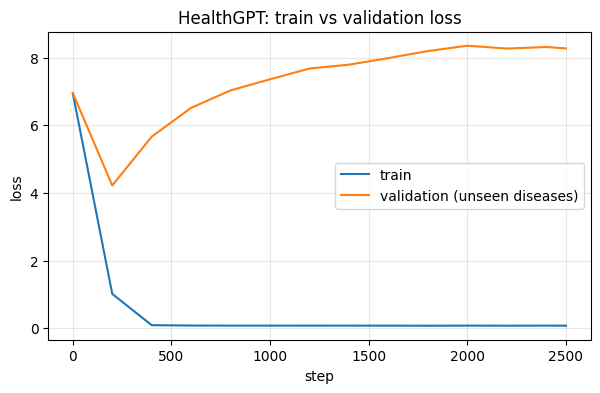

final train loss 0.077 | final val loss 8.269


In [12]:
# ---- Run A: validation run (train on 90%, validate on held-out 10%) ----
val_model, hist = train_model(train_enc, val_enc, MAX_STEPS, "A: 90/10")

plt.figure(figsize=(7, 4))
plt.plot(hist["step"], hist["train"], label="train")
plt.plot(hist["step"], hist["val"], label="validation (unseen diseases)")
plt.xlabel("step"); plt.ylabel("loss"); plt.legend(); plt.title("HealthGPT: train vs validation loss")
plt.grid(alpha=0.3)
plt.savefig(os.path.join(OUT_DIR, "loss_curve.png"), dpi=150, bbox_inches="tight")
plt.show()
print(f"final train loss {hist['train'][-1]:.3f} | final val loss {hist['val'][-1]:.3f}")

In [13]:
# ---- Run B: final model (train on 100% of the data) ----
CONFIG = dict(vocab_size=vocab_size, block_size=BLOCK_SIZE, n_layer=N_LAYER,
              n_head=N_HEAD, n_embd=N_EMBD, dropout=DROPOUT)
if TRAIN_FINAL_ON_ALL:
    model, hist_final = train_model(all_enc, None, MAX_STEPS, "B: all data")
else:
    model = val_model
model.eval()

ckpt_path = os.path.join(OUT_DIR, "healthgpt_final.pt")
torch.save({"model": model.state_dict(), "config": CONFIG, "known_diseases": sorted(KNOWN)}, ckpt_path)
print("Saved final model to", ckpt_path)

[B: all data] step     0 | train 6.923 | val nan |     0s
[B: all data] step   200 | train 1.182 | val nan |     5s
[B: all data] step   400 | train 0.096 | val nan |     9s
[B: all data] step   600 | train 0.082 | val nan |    14s
[B: all data] step   800 | train 0.080 | val nan |    19s
[B: all data] step  1000 | train 0.078 | val nan |    23s
[B: all data] step  1200 | train 0.078 | val nan |    28s
[B: all data] step  1400 | train 0.079 | val nan |    32s
[B: all data] step  1600 | train 0.079 | val nan |    37s
[B: all data] step  1800 | train 0.078 | val nan |    41s
[B: all data] step  2000 | train 0.078 | val nan |    46s
[B: all data] step  2200 | train 0.077 | val nan |    51s
[B: all data] step  2400 | train 0.078 | val nan |    55s
[B: all data] step  2500 | train 0.078 | val nan |    58s
Saved final model to /content/drive/MyDrive/healthgpt/healthgpt_final.pt


## Step 7: Ask HealthGPT
The prompt is exactly the training template: `disease: <name>` + newline + `care:`. The model continues it token by token (temperature + top-k sampling) and stops at `<END>`.

- **Lower temperature** (0.1-0.4) = safer, closer to the training text. Higher = more creative but more likely to be wrong.
- If you ask about a disease that is **not in the training data**, the model will make something up (hallucination), so the function warns you.

In [14]:
@torch.no_grad()
def generate(prompt, max_new_tokens=110, temperature=0.2, top_k=5):
    ids = tokenizer.encode(prompt).ids
    x = torch.tensor([ids], dtype=torch.long, device=device)
    for _ in range(max_new_tokens):
        with amp_ctx:
            logits, _ = model(x[:, -BLOCK_SIZE:])
        logits = logits[:, -1, :].float() / max(temperature, 1e-4)
        if top_k:
            kth = torch.topk(logits, min(top_k, logits.size(-1)))[0][:, [-1]]
            logits[logits < kth] = float("-inf")
        nxt = torch.multinomial(F.softmax(logits, dim=-1), num_samples=1)
        if nxt.item() == END_ID:                     # stop at <END>
            break
        x = torch.cat([x, nxt], dim=1)
    return tokenizer.decode(x[0].tolist())

def ask(disease, temperature=0.2, top_k=5):
    d = clean(disease)
    text = generate(f"disease: {d}\ncare:", temperature=temperature, top_k=top_k)
    care = text.split("care:", 1)[-1].strip()
    print(f"DISEASE: {d}")
    if d not in KNOWN:
        print("WARNING: this disease was NOT in the training data, so the answer below is unreliable (made up).")
    print(f"CARE: {care}")
    print(SAFETY_NOTE)
    print("-" * 70)

for name in ["common cold", "malaria", "dengue", "migraine", "food poisoning", "typhoid fever"]:
    ask(name)

DISEASE: common cold
CARE: rest well, drink plenty of warm fluids, gargle warm salt water for a sore throat and use steam inhalation for a blocked nose. see a doctor if fever lasts more than 3 days or breathing becomes difficult.
NOTE: educational project only, not medical advice. Please see a doctor.
----------------------------------------------------------------------
DISEASE: malaria
CARE: see a doctor immediately for a blood test and prescribed antimalarial medicine. rest and drink plenty of fluids. use mosquito nets, repellents and remove standing water to prevent it. get urgent help for confusion, fits or severe weakness.
NOTE: educational project only, not medical advice. Please see a doctor.
----------------------------------------------------------------------
DISEASE: dengue
CARE: rest, drink plenty of fluids and use paracetamol for fever. avoid aspirin and ibuprofen. see a doctor for a blood test. go to hospital urgently for severe stomach pain, persistent vomiting, bleedin

## Step 8: Chat with it (type a disease, press Enter)
Type `quit` to stop. Run this cell and use the input box that appears under it.

In [18]:
#@title Interactive HealthGPT
print("Known diseases:", ", ".join(sorted(KNOWN)))
print("\nType a disease name (or 'quit').")
while True:
    q = input("\nDisease: ").strip()
    if q.lower() in ("quit", "exit", "q", ""):
        print("Bye. Stay healthy, and see a doctor when unsure!")
        break
    ask(q)

Known diseases: acid reflux, acne, allergic rhinitis, anemia, appendicitis, asthma, athlete foot, back pain, bronchitis, chickenpox, chikungunya, cholera, common cold, conjunctivitis, constipation, cough, covid-19, dehydration, dengue, diabetes, diarrhea, ear infection, eczema, fever, food poisoning, gastroenteritis, hand foot and mouth disease, headache, heart attack, heat stroke, hepatitis a, hiccups, high blood pressure, indigestion, influenza, insect bite, insomnia, kidney stones, malaria, measles, migraine, minor burn, minor cut, motion sickness, mouth ulcer, mumps, muscle cramps, nosebleed, pneumonia, ringworm, scabies, sinusitis, sore throat, sprain, stomach ulcer, stress, stroke, sunburn, tonsillitis, toothache, tuberculosis, typhoid, urinary tract infection, vomiting

Type a disease name (or 'quit').
DISEASE: acidity
CARE: drink plenty of water for paracetamol for fever and stiff neck, breathe. see a doctor if the face or after a week, you cannot pass urine.
NOTE: educational 

## Notes and next steps (for your presentation)
- **Limits:** tiny dataset, so answers can be wrong or repetitive; it can invent plausible-sounding advice (hallucination); it does not understand symptoms, age or severity.
- **Better data:** grow the dataset with entries you verify from WHO / NHS / ministry sites and cite them. Add them via `CUSTOM_CSV` (columns `disease,care`).
- **Bigger model / more steps:** raise `N_LAYER`, `N_EMBD`, `MAX_STEPS` once you have more data.
- **Safer:** add retrieval so answers come from real documents, and always show the safety note and doctor referral (already in `ask()`).
- **Files saved in the output folder:** `tokenizer/` (vocab.json + merges.txt), `healthgpt_final.pt`, `loss_curve.png`.